First rows:
   CustomerID  Age  Gender  Tenure_months  Monthly_charges        Contract  \
0       0001   23  Female             63            94.07  Month-to-month   
1       0002   62  Female              5            51.88        Two year   
2       0003   55  Female             29            48.66  Month-to-month   
3       0004   43  Female             33            81.49  Month-to-month   
4       0005   42    Male             57            94.71  Month-to-month   

   Support_calls  Churn  
0              3      1  
1              2      0  
2              1      1  
3              1      1  
4              1      1   

Churn distribution:
 Churn
0    0.507
1    0.493
Name: proportion, dtype: float64 

Intercept (b0): -0.0721
          Feature  Coefficient (log-odds)  Odds ratio
    Support_calls                0.570316    1.768826
  Monthly_charges                0.466042    1.593673
      Gender_Male                0.059418    1.061218
              Age               -0.132448 

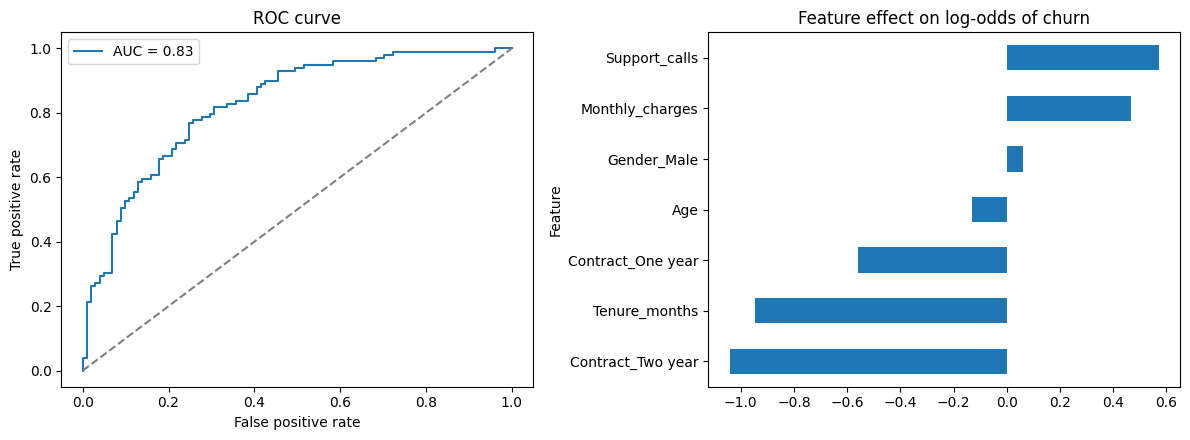


Churn probability for new customer: 98.3%


In [1]:
"""
Logistic Regression Exercise - Telecom Customer Churn
Churn = 1 -> customer leaves, Churn = 0 -> customer stays

Model: log(p / (1 - p)) = b0 + b1*x1 + b2*x2 + ... + bk*xk
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve,
)

# ---------------------------------------------------------------------------
# 1. Create a synthetic dataset of 1000 customers
#    (replace this block with pd.read_csv("your_file.csv") for real data)
# ---------------------------------------------------------------------------
rng = np.random.default_rng(42)
n = 1000

df = pd.DataFrame({
    "CustomerID": [f"{i:04d}" for i in range(1, n + 1)],
    # demographic info
    "Age": rng.integers(18, 75, n),
    "Gender": rng.choice(["Male", "Female"], n),
    # account info
    "Tenure_months": rng.integers(1, 72, n),
    "Monthly_charges": rng.normal(70, 25, n).clip(20, 150).round(2),
    "Contract": rng.choice(["Month-to-month", "One year", "Two year"], n, p=[0.55, 0.25, 0.20]),
    "Support_calls": rng.poisson(1.5, n),
})

# True (hidden) relationship used to generate the target variable
logit = (
    -1.0
    - 0.04 * df["Tenure_months"]
    + 0.02 * df["Monthly_charges"]
    + 0.45 * df["Support_calls"]
    + np.where(df["Contract"] == "Month-to-month", 1.2, 0)
    + np.where(df["Contract"] == "Two year", -1.0, 0)
)
prob = 1 / (1 + np.exp(-logit))
df["Churn"] = rng.binomial(1, prob)

print("First rows:\n", df.head(), "\n")
print("Churn distribution:\n", df["Churn"].value_counts(normalize=True), "\n")

# ---------------------------------------------------------------------------
# 2. Prepare features
# ---------------------------------------------------------------------------
X = df.drop(columns=["CustomerID", "Churn"])
y = df["Churn"]

# One-hot encode categorical variables (drop_first avoids multicollinearity)
X = pd.get_dummies(X, columns=["Gender", "Contract"], drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale numeric features
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# ---------------------------------------------------------------------------
# 3. Train the logistic regression model
# ---------------------------------------------------------------------------
model = LogisticRegression(max_iter=1000)
model.fit(X_train_s, y_train)

coefs = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient (log-odds)": model.coef_[0],
    "Odds ratio": np.exp(model.coef_[0]),
}).sort_values("Coefficient (log-odds)", ascending=False)

print("Intercept (b0):", round(model.intercept_[0], 4))
print(coefs.to_string(index=False), "\n")

# ---------------------------------------------------------------------------
# 4. Evaluate
# ---------------------------------------------------------------------------
y_prob = model.predict_proba(X_test_s)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1-score :", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 3))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\n", classification_report(y_test, y_pred, target_names=["Stays (0)", "Churns (1)"]))

# ---------------------------------------------------------------------------
# 5. Plots: ROC curve and coefficients
# ---------------------------------------------------------------------------
fpr, tpr, _ = roc_curve(y_test, y_prob)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.2f}")
ax[0].plot([0, 1], [0, 1], "--", color="gray")
ax[0].set_xlabel("False positive rate")
ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curve")
ax[0].legend()

coefs.sort_values("Coefficient (log-odds)").plot.barh(
    x="Feature", y="Coefficient (log-odds)", ax=ax[1], legend=False
)
ax[1].set_title("Feature effect on log-odds of churn")

plt.tight_layout()
plt.savefig("churn_results.png", dpi=150)
plt.show()

# ---------------------------------------------------------------------------
# 6. Predict for a new customer
# ---------------------------------------------------------------------------
new_customer = pd.DataFrame([{
    "Age": 35, "Tenure_months": 6, "Monthly_charges": 95.0, "Support_calls": 4,
    "Gender_Male": 1, "Contract_One year": 0, "Contract_Two year": 0,
}])[X.columns]

p = model.predict_proba(scaler.transform(new_customer))[0, 1]
print(f"\nChurn probability for new customer: {p:.1%}")

First rows:
   CustomerID  Age  Gender  Tenure_months  Monthly_charges Contract_Length  \
0       0001   23  Female             63            94.07  Month-to-month   
1       0002   62  Female              5            51.88        Two year   
2       0003   55  Female             29            48.66  Month-to-month   
3       0004   43  Female             33            81.49  Month-to-month   
4       0005   42    Male             57            94.71  Month-to-month   

  Contract_Type  Support_calls  Churn  
0       Premium              0      1  
1       Premium              1      0  
2       Premium              2      0  
3         Basic              0      1  
4         Basic              3      0   

Churn distribution:
 Churn
1    0.556
0    0.444
Name: proportion, dtype: float64 

Intercept (b0): 0.3045
                 Feature  Coefficient (log-odds)  Odds ratio
         Monthly_charges                0.575732    1.778432
           Support_calls                0.508125    1

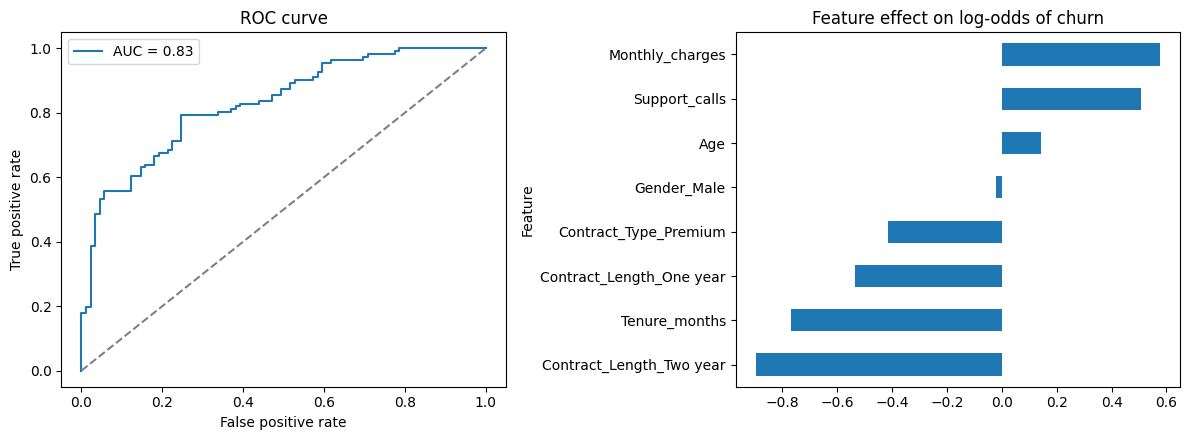


Churn probability for new customer: 98.5%


In [2]:
"""
Logistic Regression Exercise - Telecom Customer Churn
Churn = 1 -> customer leaves, Churn = 0 -> customer stays

Model: log(p / (1 - p)) = b0 + b1*x1 + b2*x2 + ... + bk*xk
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve,
)

# ---------------------------------------------------------------------------
# 1. Create a synthetic dataset of 1000 customers
#    (replace this block with pd.read_csv("your_file.csv") for real data)
# ---------------------------------------------------------------------------
rng = np.random.default_rng(42)
n = 1000

df = pd.DataFrame({
    "CustomerID": [f"{i:04d}" for i in range(1, n + 1)],
    # demographic info
    "Age": rng.integers(18, 75, n),
    "Gender": rng.choice(["Male", "Female"], n),
    # account info
    "Tenure_months": rng.integers(1, 72, n),
    "Monthly_charges": rng.normal(70, 25, n).clip(20, 150).round(2),
    "Contract_Length": rng.choice(["Month-to-month", "One year", "Two year"], n, p=[0.55, 0.25, 0.20]),
    "Contract_Type": rng.choice(["Basic", "Premium"], n, p=[0.6, 0.4]),
    "Support_calls": rng.poisson(1.5, n),
})

# True (hidden) relationship used to generate the target variable
logit = (
    -1.0
    - 0.04 * df["Tenure_months"]
    + 0.02 * df["Monthly_charges"]
    + 0.45 * df["Support_calls"]
    + np.where(df["Contract_Length"] == "Month-to-month", 1.2, 0)
    + np.where(df["Contract_Length"] == "Two year", -1.0, 0)
    + np.where(df["Contract_Type"] == "Basic", 0.6, -0.4)  # Basic churns more than Premium
)
prob = 1 / (1 + np.exp(-logit))
df["Churn"] = rng.binomial(1, prob)

print("First rows:\n", df.head(), "\n")
print("Churn distribution:\n", df["Churn"].value_counts(normalize=True), "\n")

# ---------------------------------------------------------------------------
# 2. Prepare features
# ---------------------------------------------------------------------------
X = df.drop(columns=["CustomerID", "Churn"])
y = df["Churn"]

# One-hot encode categorical variables (drop_first avoids multicollinearity)
X = pd.get_dummies(X, columns=["Gender", "Contract_Length", "Contract_Type"], drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale numeric features
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# ---------------------------------------------------------------------------
# 3. Train the logistic regression model
# ---------------------------------------------------------------------------
model = LogisticRegression(max_iter=1000)
model.fit(X_train_s, y_train)

coefs = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient (log-odds)": model.coef_[0],
    "Odds ratio": np.exp(model.coef_[0]),
}).sort_values("Coefficient (log-odds)", ascending=False)

print("Intercept (b0):", round(model.intercept_[0], 4))
print(coefs.to_string(index=False), "\n")

# ---------------------------------------------------------------------------
# 4. Evaluate
# ---------------------------------------------------------------------------
y_prob = model.predict_proba(X_test_s)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1-score :", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 3))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\n", classification_report(y_test, y_pred, target_names=["Stays (0)", "Churns (1)"]))

# ---------------------------------------------------------------------------
# 5. Plots: ROC curve and coefficients
# ---------------------------------------------------------------------------
fpr, tpr, _ = roc_curve(y_test, y_prob)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.2f}")
ax[0].plot([0, 1], [0, 1], "--", color="gray")
ax[0].set_xlabel("False positive rate")
ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curve")
ax[0].legend()

coefs.sort_values("Coefficient (log-odds)").plot.barh(
    x="Feature", y="Coefficient (log-odds)", ax=ax[1], legend=False
)
ax[1].set_title("Feature effect on log-odds of churn")

plt.tight_layout()
plt.savefig("churn_results.png", dpi=150)
plt.show()

# ---------------------------------------------------------------------------
# 6. Predict for a new customer
# ---------------------------------------------------------------------------
new_customer = pd.DataFrame([{
    "Age": 35, "Tenure_months": 6, "Monthly_charges": 95.0, "Support_calls": 4,
    "Gender_Male": 1, "Contract_Length_One year": 0, "Contract_Length_Two year": 0,
    "Contract_Type_Premium": 0,  # 0 = Basic, 1 = Premium
}])[X.columns]

p = model.predict_proba(scaler.transform(new_customer))[0, 1]
print(f"\nChurn probability for new customer: {p:.1%}")